NOTE: SHAP har prediction ko features ke hisson mein tod deta hai:

prediction = base value + (feature 1 ka asar) + (feature 2 ka asar) + ...

Har customer ke liye har feature ko ek number milta hai. Positive number churn risk badhata hai, negative ghatata hai. Yeh interview mein isliye strong point hai ki tum sirf “model kya predict karta hai” nahi, “kyun” bhi bata sakte ho.

SHAP kya NAHI batata (README mein bhi likhna):

1. Causation nahi. “OverdueRatio zyada hone par risk badhta hai” ek pattern hai. Is se yeh sabit nahi hota ki ratio kam karne se customer ruk jaayega. Uske liye experiment (A/B test) chahiye.
2. Correlated features credit baant lete hain. Frequency aur Orders_last90 jaise features ek doosre ke saath importance split kar lete hain, to dono kamzor dikh sakte hain.
3. Units alag ho sakte hain. XGBoost aur LogReg mein SHAP log-odds mein hota hai, Random Forest mein probability mein. Class weighting ki wajah se base value asli churn rate nahi hota. Kisi bhi number ko “X% risk” mat padhna, ranking aur direction padho.

Aaj ke rules:

1. Model, features aur threshold kuch nahi badlega. SHAP descriptive hai. Agar koi feature bekar dikhe, use abhi hatana test-informed selection ban jaata hai. Jo mile use report mein likho.
2. Main analysis train ke sample par hogi. Test par sirf stability check, aur SHAP labels use hi nahi karta.
3. Kuch bhi dikhne se pehle additivity check pass hona chahiye. Agar nahi, to explainer galat model par laga hai.

1. src/models/explain.py (Streamlit aur agent ke liye bhi reuse hoga)

In [1]:
"""SHAP helpers: model-type ke hisaab se explainer, churn (class 1) ke values return."""
import numpy as np
import pandas as pd
import shap
from sklearn.pipeline import Pipeline


def _positive_class(sv):
    """Alag shap versions alag shape deti hain. Class 1 ke liye (n, features) array return karo."""
    if isinstance(sv, list):
        return np.asarray(sv[1])
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv


def _base_value(ev):
    ev = np.atleast_1d(np.asarray(ev, dtype=float))
    return float(ev[-1])


def _shap_for_estimator(est, Xt, bg_t):
    if hasattr(est, 'coef_'):                                  # linear model
        ex = shap.LinearExplainer(est, bg_t)
        values = _positive_class(ex.shap_values(Xt))
        output, space = est.decision_function(Xt), 'log-odds'
    else:                                                      # tree-based
        ex = shap.TreeExplainer(est)
        values = _positive_class(ex.shap_values(Xt))
        if type(est).__name__ == 'XGBClassifier':
            output, space = est.predict(Xt, output_margin=True), 'log-odds'
        else:
            output, space = est.predict_proba(Xt)[:, 1], 'probability'
    return values, _base_value(ex.expected_value), np.asarray(output, dtype=float), space


def explain(model, X: pd.DataFrame, background: pd.DataFrame | None = None) -> dict:
    """values (DataFrame, X ke hi columns/order mein), base, output, space, gap return karta hai.
    gap = max |sum(values) + base - model ka asli output|. Ye ~0 hona chahiye."""
    X = X.reset_index(drop=True)
    if isinstance(model, Pipeline):
        prep, est = model[:-1], model[-1]
        names = [n.split('__')[-1] for n in prep.get_feature_names_out()]
        Xt = pd.DataFrame(prep.transform(X), columns=names)
        bg_t = pd.DataFrame(prep.transform(X if background is None else background), columns=names)
    else:
        est, Xt = model, X
        bg_t = X if background is None else background

    values, base, output, space = _shap_for_estimator(est, Xt, bg_t)
    values = pd.DataFrame(values, columns=Xt.columns)[list(X.columns)]   # ColumnTransformer ne order badla ho to wapas theek
    gap = float(np.abs(values.sum(axis=1).to_numpy() + base - output).max())
    return {'values': values, 'base': base, 'output': output, 'space': space, 'gap': gap}


def reason_codes(values_row, x_row: pd.Series, k: int = 3):
    """Top-k features jo is customer ka churn risk badhate hain (sirf positive SHAP): [(feature, value, shap)]."""
    s = pd.Series(np.asarray(values_row), index=x_row.index)
    top = s[s > 0].sort_values(ascending=False).head(k)
    return [(f, float(x_row[f]), float(v)) for f, v in top.items()]

c:\Users\rajat\OneDrive\Desktop\ecommerce-churn-project\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Column order wala reindex zaroori hai. LogReg ki ColumnTransformer scaled columns ko pehle rakhti hai, aur beeswarm plot mein colors galat features par lag jaate agar order mismatch hota.

2. setup

In [6]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('.').resolve().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
import warnings; warnings.filterwarnings('ignore')
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance
from src.models.explain import explain, reason_codes

card = json.load(open('../../reports/final_model_card.json'))
model = joblib.load('../model/final_model.joblib')
final_name = card['model']

X_tr = pd.read_csv('../../data/processed/X_train_v2.csv').astype(float)
X_te = pd.read_csv('../../data/processed/X_test_v2.csv').astype(float)
y_tr = pd.read_csv('../../data/processed/y_train.csv').squeeze().values
y_te = pd.read_csv('../../data/processed/y_test.csv').squeeze().values
assert list(X_tr.columns) == card['features'], "feature order model card se match nahi karta"
print(final_name, '|', type(model).__name__, '| shap', shap.__version__)

rng = np.random.default_rng(0)
idx = rng.choice(len(X_tr), size=min(1000, len(X_tr)), replace=False)
X_s = X_tr.iloc[idx].reset_index(drop=True)
y_s = y_tr[idx]

XGBoost | XGBClassifier | shap 0.54.1


3. SHAP nikalo aur additivity check karo

In [7]:
r = explain(model, X_s, background=X_tr)
sv, base, space = r['values'], r['base'], r['space']

print(f"Space: {space} | base value: {base:.3f} | additivity gap: {r['gap']:.2e}")
assert r['gap'] < 1e-3, "SHAP values model ke output se match nahi karte, aage mat badho"

if space == 'log-odds':
    print(f"Base value probability mein: {1 / (1 + np.exp(-base)):.3f} | asli churn rate: {y_tr.mean():.3f}")
else:
    print(f"Base value: {base:.3f} | asli churn rate: {y_tr.mean():.3f}")

Space: log-odds | base value: -0.004 | additivity gap: 1.67e-06
Base value probability mein: 0.499 | asli churn rate: 0.566


Base value aur asli churn rate alag ho sakte hain. Class weighting ne model ko churn ki taraf jhukaya hai, isliye yeh normal hai. Log-odds ka ek quick matlab: +0.5 log-odds ≈ churn ke odds 1.65 guna (e^0.5).

4. Global importance: kaunse features sabse zyada matter karte hain

                      mean_abs_shap  share_%       cum_%
OrdersPerMonth                0.357   24.775   24.775000
Recency                       0.270   18.726   43.500999
UniqueProducts                0.170   11.819   55.320000
RunRateValue90_log            0.129    8.975   64.294998
Orders_prev90                 0.083    5.735   70.028999
Spend_last90_log              0.081    5.622   75.652000
OverdueRatio                  0.063    4.356   80.007004
Monetary_log                  0.061    4.202   84.209000
AvgGapDays                    0.058    4.040   88.249001
Orders_last90                 0.055    3.811   92.059998
Frequency                     0.048    3.331   95.390999
LastGapDays                   0.019    1.341   96.733002
Tenure                        0.015    1.007   97.739998
AvgLinesPerOrder              0.011    0.782   98.522003
AvgOrderValue                 0.008    0.540   99.063004
AvgUnitsPerOrder              0.006    0.405   99.468002
MaxOrderValue_log             0

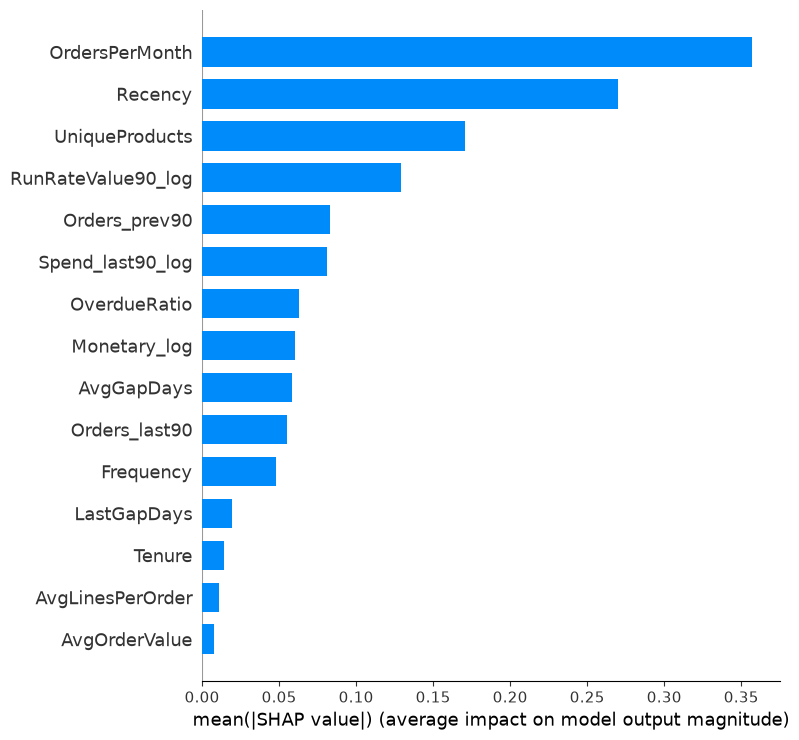

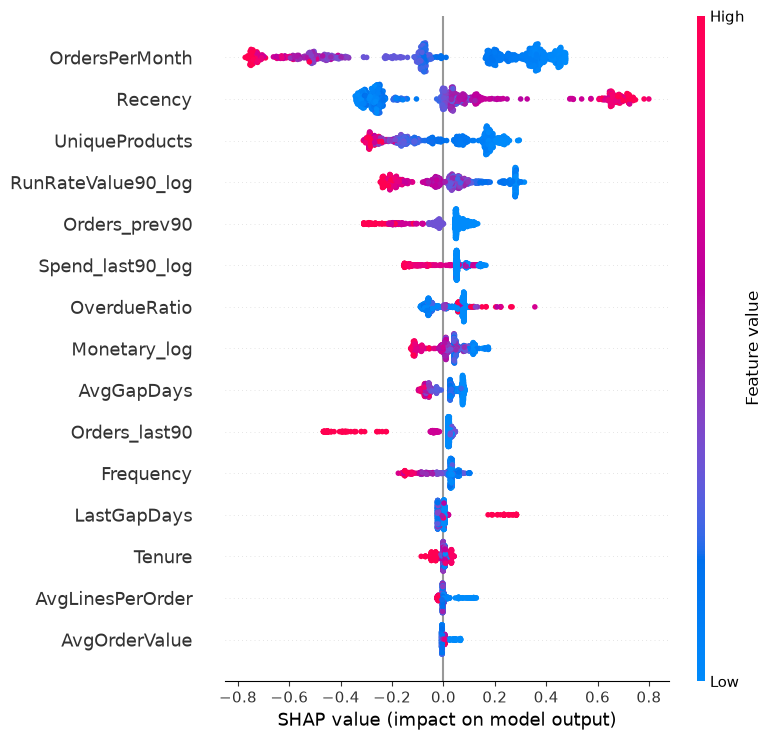

In [9]:
imp = sv.abs().mean().sort_values(ascending=False)
imp_tbl = pd.DataFrame({'mean_abs_shap': imp, 'share_%': imp / imp.sum() * 100})
imp_tbl['cum_%'] = imp_tbl['share_%'].cumsum()
print(imp_tbl.round(3))

plt.figure()
shap.summary_plot(sv.values, X_s, plot_type='bar', show=False, max_display=15)
plt.tight_layout(); plt.savefig('../../reports/shap_bar_day85b.png', dpi=150, bbox_inches='tight'); plt.show()

plt.figure()
shap.summary_plot(sv.values, X_s, show=False, max_display=15)
plt.tight_layout(); plt.savefig('../../reports/shap_summary_day85b.png', dpi=150, bbox_inches='tight'); plt.show()

Beeswarm kaise padho:

- Har dot ek customer hai.
- x-axis: us customer ke liye feature ne risk kitna badhaya (right) ya ghataya (left).
- Rang: feature ki value (laal = zyada, neela = kam).
- Agar OverdueRatio ke laal dots right mein hain, to ratio zyada hone par risk zyada hai. Yeh business sense banata hai ya nahi? Wo bhi dekho.
- Agar kisi feature ka direction ulta (kam value par risk zyada) dikhe aur wo samajh na aaye, to usse pehle correlated features se check karo.

5. Kya in explanations par bharosa kar sakte hain? (3 checks)

In [10]:
# (a) Red flag: ek feature sab kuch to nahi kha raha?
top_share = imp_tbl['share_%'].iloc[0]
print(f"Top feature ({imp_tbl.index[0]}) ka share: {top_share:.1f}%")
if top_share > 50:
    print("SHAK: ek feature 50%+ explain kar raha hai. Day 82 ka invariance test aur leakage dobara check karo.")

# (b) Stability: test sample par bhi ranking wahi hai?
te_idx = rng.choice(len(X_te), size=min(500, len(X_te)), replace=False)
X_ts = X_te.iloc[te_idx].reset_index(drop=True)
imp_te = explain(model, X_ts, background=X_tr)['values'].abs().mean()
rho, _ = spearmanr(imp.reindex(X_tr.columns), imp_te.reindex(X_tr.columns))
print(f"Train vs test SHAP ranking agreement (Spearman): {rho:.2f}")
print("Top-5 common:", len(set(imp.index[:5]) & set(imp_te.sort_values(ascending=False).index[:5])), "/ 5")

# (c) Doosre tareeke se confirm: permutation importance (AUC drop)
pi = permutation_importance(model, X_te, y_te, scoring='roc_auc', n_repeats=10, random_state=0, n_jobs=-1)
pi_s = pd.Series(pi.importances_mean, index=X_te.columns)
rho_pi, _ = spearmanr(imp.reindex(X_te.columns), pi_s)
print(f"SHAP vs permutation importance agreement (Spearman): {rho_pi:.2f}")
print(pd.DataFrame({'SHAP rank': imp.rank(ascending=False), 'Permutation rank': pi_s.rank(ascending=False)})
        .sort_values('SHAP rank').head(8))

Top feature (OrdersPerMonth) ka share: 24.8%
Train vs test SHAP ranking agreement (Spearman): 1.00
Top-5 common: 5 / 5
SHAP vs permutation importance agreement (Spearman): 0.84
                    SHAP rank  Permutation rank
OrdersPerMonth            1.0               1.0
Recency                   2.0               2.0
UniqueProducts            3.0               3.0
RunRateValue90_log        4.0               8.0
Orders_prev90             5.0               7.0
Spend_last90_log          6.0              11.0
OverdueRatio              7.0               4.0
Monetary_log              8.0               6.0


Test par yeh sirf descriptive checks hain, koi decision unse nahi nikalna. Agar agreement kam ho (jaise 0.5 se neeche) to likho ki correlated features ki wajah se ranking unstable hai. Chhota test set bhi isko hila sakta hai. Un features ko abhi hatana nahi hai.

6. Grouped SHAP: correlated features ko ek parivar mein jodo

Day 82 ke features ek-doosre se ladte hain credit ke liye. Parivar ke hisaab se jodne par kahani zyada stable hoti hai.

Frequency / volume    38.200001
Recency / timing      27.500000
Monetary / value      18.400000
Basket / product      14.600000
Tenure                 1.200000
Geography              0.200000
dtype: float32


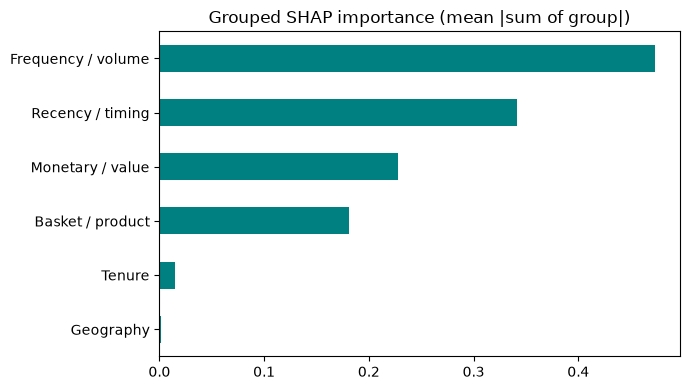

In [12]:
cols = list(X_s.columns)
groups = {
    'Recency / timing':   ['Recency', 'LastGapDays', 'OverdueRatio', 'AvgGapDays'],
    'Frequency / volume': ['Frequency', 'OrdersPerMonth', 'Orders_last90', 'Orders_prev90', 'OrderTrend', 'SingleOrder'],
    'Monetary / value':   ['Monetary_log', 'AvgOrderValue', 'RunRateValue90_log', 'Spend_last90_log', 'MaxOrderValue_log'],
    'Basket / product':   ['UniqueProducts', 'AvgUnitsPerOrder', 'AvgLinesPerOrder'],
    'Tenure':             ['Tenure'],
    'Geography':          [c for c in cols if c.startswith('Region_')],
}
assigned = [c for v in groups.values() for c in v]
assert sorted(assigned) == sorted(cols), f"Mismatch: {set(cols) ^ set(assigned)}"

grp = pd.DataFrame({g: sv[c].sum(axis=1) for g, c in groups.items()})
grp_imp = grp.abs().mean().sort_values(ascending=False)
print((grp_imp / grp_imp.sum() * 100).round(1))

grp_imp.sort_values().plot.barh(figsize=(7, 4), color='teal')
plt.title('Grouped SHAP importance (mean |sum of group|)')
plt.tight_layout(); plt.savefig('../../reports/shap_groups_day85b.png', dpi=150); plt.show()

Group ke andar ke SHAP values pehle jodte hain, phir absolute lete hain. Is se group ke andar ke features ek doosre ko cancel kar sakte hain, jo sahi hai (kyunki wo ek hi baat alag tareeke se keh rahe hain). Note: OrderTrend exactly Orders_last90 - Orders_prev90 hai, isliye in teeno ke beech credit ka baantna aur bhi zyada hoga.

7. Dependence plots: feature badalne par risk kaise badalta hai

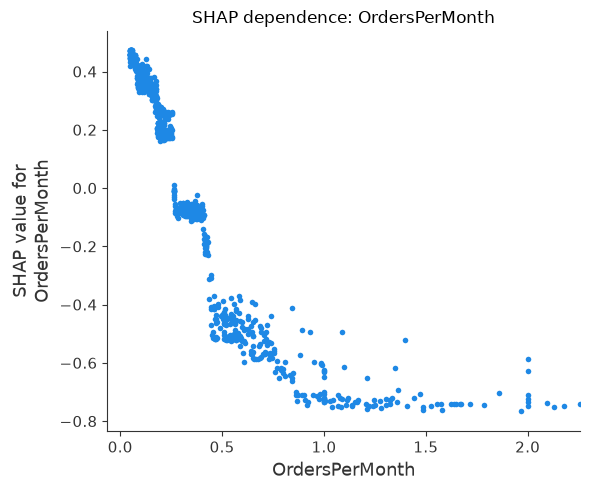

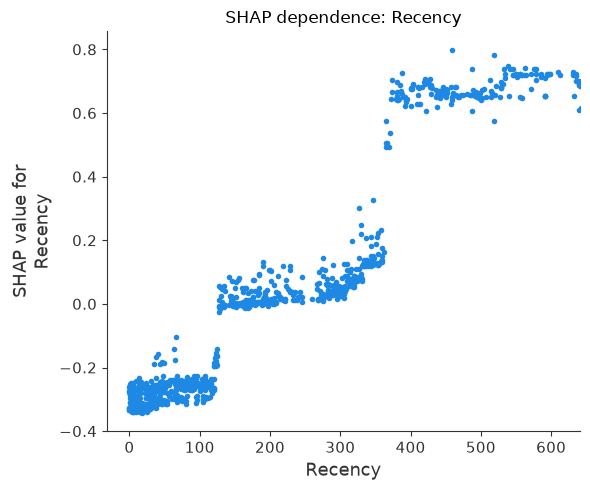

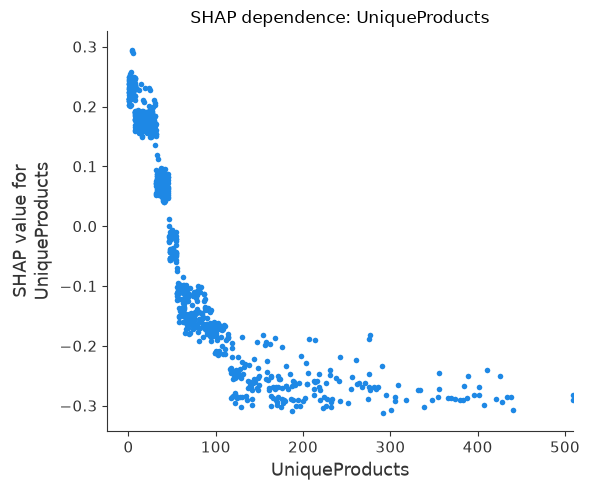

In [14]:
for f in imp.index[:3]:
    shap.dependence_plot(f, sv.values, X_s, interaction_index=None, xmax='percentile(99)', show=False)
    plt.title(f'SHAP dependence: {f}')
    plt.tight_layout()
    plt.savefig(f'../../reports/shap_dependence_{f}.png', dpi=150, bbox_inches='tight')
    plt.show()

Dekho ki kisi value ke upar risk achanak jump karta hai (jaise OverdueRatio 1.5 ke baad). Wahi ek business trigger ban sakta hai (“jo customer apne normal gap se 1.5 guna zyada late ho gaya, use reminder bhejo”). Phir bhi yeh ek hypothesis hai, causal claim nahi.

8. Ek-ek customer ki explanation (waterfall + reason codes)

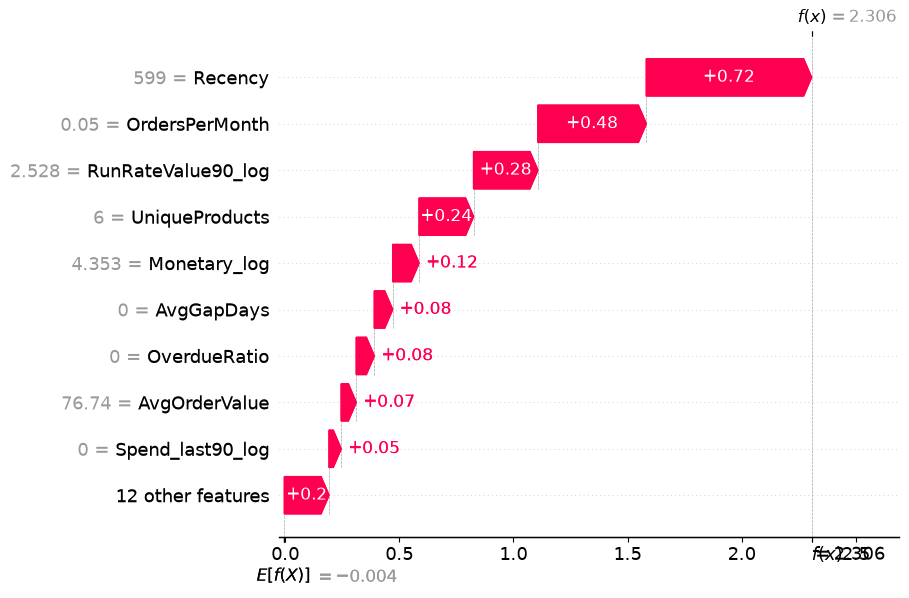

highest_risk: actual churned = 1
  Risk badhane wale top-3: Recency=599.00 (+0.72); OrdersPerMonth=0.05 (+0.48); RunRateValue90_log=2.53 (+0.28)


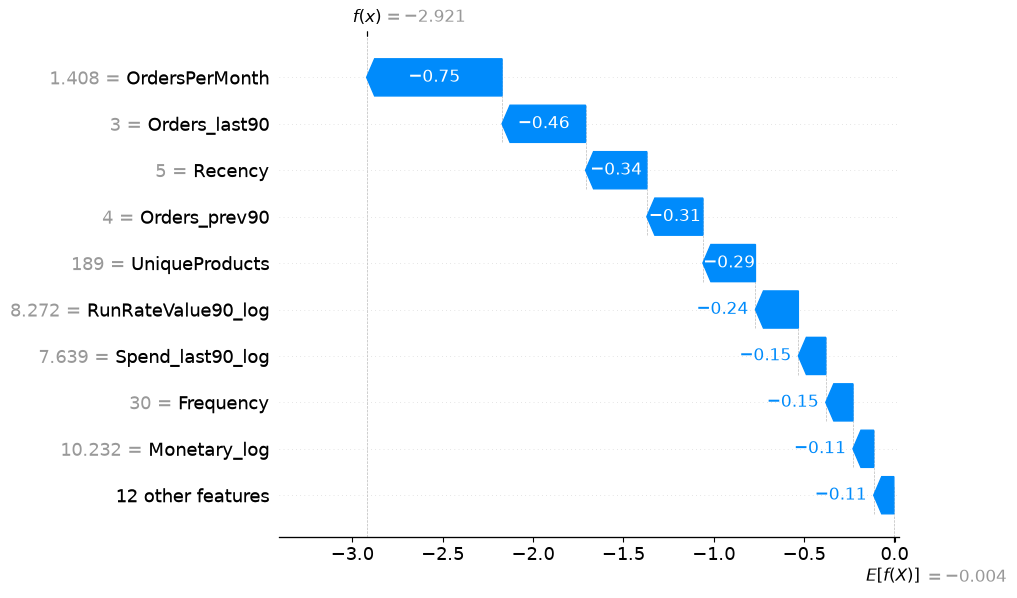

lowest_risk: actual churned = 0
  Risk badhane wale top-3: AvgGapDays=21.38 (+0.03); MaxOrderValue_log=8.26 (+0.01); AvgOrderValue=926.20 (+0.00)


In [16]:
risk = r['output']
for tag, i in [('highest_risk', int(np.argmax(risk))), ('lowest_risk', int(np.argmin(risk)))]:
    exp = shap.Explanation(values=sv.iloc[i].values, base_values=base,
                           data=X_s.iloc[i].values, feature_names=cols)
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.savefig(f'../../reports/shap_waterfall_{tag}.png', dpi=150, bbox_inches='tight')
    plt.show()
    codes = reason_codes(sv.iloc[i].values, X_s.iloc[i], k=3)
    print(f"{tag}: actual churned = {y_s[i]}")
    print("  Risk badhane wale top-3:", '; '.join(f"{f}={v:.2f} (+{s:.2f})" for f, v, s in codes))

Waterfall niche se shuru hota hai (base value), har bar ek feature ka asar dikhata hai, aur upar final prediction aata hai. Highest-risk customer ka actual label dekho. Kabhi-kabhi model sach mein galat hota hai, aur wo bhi theek hai.

reason_codes wahi function hai jo Day 89-90 ke Streamlit mein “Is customer ka risk kyun zyada hai” dikhayega, aur Phase 7 mein agent ko SHAP explanation dene mein (Day 125) kaam aayega.

9. Findings ko business ki bhasha mein badlo (markdown cell mein likho)

## What drives churn in this model (SHAP)
1. **[Top feature/group]**: [direction + ek real value, jaise "customers 1.5x past their usual gap"]. Share: [X]% of total.
2. **[Second]**: ...
3. **[Third]**: ...

**Suggested action (hypothesis, not proven cause):** [jaise "reminder trigger when OverdueRatio crosses ~X"]. To confirm, run an A/B test.

**What SHAP cannot tell us:** causation; credit is shared among correlated features (grouped view used);
values are log-odds under class weighting, so use them for ranking/direction, not as risk percentages.

Yeh paragraph interview mein “tumne model explain kaise kiya?” ka seedha jawab hai.

10. Save karo

In [17]:
imp_tbl.round(4).to_csv('../../reports/shap_importance_day85b.csv')
grp_imp.round(4).to_csv('../../reports/shap_group_importance_day85b.csv')

README ke liye note (apne numbers se bharo):

## Explainability (SHAP)
Global SHAP on [final model] shows [top group] drives [X]% of predicted risk, led by [top feature].
Direction checks out: [ek line]. Ranking is stable between train and test samples (Spearman [X]) and agrees
with permutation importance ([X]). Correlated features share credit, so grouped SHAP is reported too.
Single-customer explanations (waterfall + reason codes) are reusable in the app: `src/models/explain.py`.
SHAP shows what the model uses, not what causes churn.

practice questions:

1. Train sample mein false alarms (model ne high risk bola, customer actually churn nahi hua) aur true positives ke mean SHAP values compare karo. Kaunsa feature false alarms mein sabse zyada risk push kar raha tha? Isse model ki kamzori ka idea milta hai.
2. Apne shabdon mein (4 lines, bina jargon ke) ek manager ko samjhao ki “SHAP value” kya hota hai.
3. Ek sawaal ka jawab likho: agar SHAP dikhaye ki Region_UK ka asar bahut chhota hai, to kya hum region ko model se hata sakte hain? (Hint: Day 82-85 ke rules dhyan mein rakho.)